# GAN Assignment - Generative Adversarial Networks

**Part 1:** GANs from Scratch (sine wave, spiral, architecture comparison)
**Part 2.1:** OCTMNIST retinal images (DCGAN + cGAN extension)
**Part 2.2:** CICIDS 2017 cybersecurity traffic (Tabular GAN)
**Part 2.3:** QuickDraw birthday cake sketches (DCGAN + multi-category)

In [58]:
!pip install medmnist scipy -q

In [59]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy import linalg
import os, glob, warnings, requests, zipfile

warnings.filterwarnings('ignore')
torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"device: {device}")

for d in ['figures/part1', 'figures/part2_1', 'figures/part2_2', 'figures/part2_3']:
    os.makedirs(d, exist_ok=True)

device: cuda


---
# Part 1 - Building GANs from Scratch

## 1.1 - Sine Wave GAN

In [60]:
def generate_sine_data(n=2000):
    x = np.random.uniform(-np.pi, np.pi, n)
    y = np.sin(x) + np.random.normal(0, 0.1, n)
    return torch.FloatTensor(np.column_stack([x, y]))

def generate_spiral_data(n=2000, noise=0.03):
    half = n // 2
    theta = np.linspace(0, 4*np.pi, half)
    r = theta / (4*np.pi)
    x1 = r * np.cos(theta) + np.random.normal(0, noise, half)
    y1 = r * np.sin(theta) + np.random.normal(0, noise, half)
    x2 = r * np.cos(theta + np.pi) + np.random.normal(0, noise, half)
    y2 = r * np.sin(theta + np.pi) + np.random.normal(0, noise, half)
    x = np.concatenate([x1, x2])
    y = np.concatenate([y1, y2])
    return torch.FloatTensor(np.column_stack([x, y]))

In [61]:
class Generator(nn.Module):
    def __init__(self, z_dim=2, hidden=64, out=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, out),
        )
    def forward(self, z):
        return self.net(z)

class Discriminator(nn.Module):
    def __init__(self, inp=2, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(inp, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, 1), nn.Sigmoid(),
        )
    def forward(self, x):
        return self.net(x)

In [62]:
def train_gan(G, D, data, epochs=5000, bs=256, z_dim=2, lr=0.0002):
    criterion = nn.BCELoss()
    g_opt = optim.Adam(G.parameters(), lr=lr)
    d_opt = optim.Adam(D.parameters(), lr=lr)
    g_losses, d_losses = [], []

    for ep in range(epochs):
        idx = np.random.randint(0, len(data), bs)
        real = data[idx].to(device)
        ones = torch.ones(bs, 1, device=device)
        zeros = torch.zeros(bs, 1, device=device)

        # discriminator
        d_opt.zero_grad()
        z = torch.randn(bs, z_dim, device=device)
        d_loss = criterion(D(real), ones) + criterion(D(G(z).detach()), zeros)
        d_loss.backward(); d_opt.step()

        # generator
        g_opt.zero_grad()
        z = torch.randn(bs, z_dim, device=device)
        g_loss = criterion(D(G(z)), ones)
        g_loss.backward(); g_opt.step()

        g_losses.append(g_loss.item())
        d_losses.append(d_loss.item())
        if (ep+1) % 1000 == 0:
            print(f"  epoch {ep+1}/{epochs} | d_loss={d_loss.item():.4f} g_loss={g_loss.item():.4f}")

    return g_losses, d_losses

def plot_comparison(real_data, gen, z_dim=2, n=1000, title="", savepath=None):
    gen.eval()
    with torch.no_grad():
        fake_pts = gen(torch.randn(n, z_dim, device=device)).cpu().numpy()
    gen.train()
    real_pts = real_data[:n].numpy()
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.scatter(real_pts[:,0], real_pts[:,1], s=10, alpha=0.5, c='blue')
    ax1.set_title('Real Data'); ax1.set_xlabel('x'); ax1.set_ylabel('y'); ax1.grid(True, alpha=0.3)
    ax2.scatter(fake_pts[:,0], fake_pts[:,1], s=10, alpha=0.5, c='red')
    ax2.set_title('Generated Data'); ax2.set_xlabel('x'); ax2.set_ylabel('y'); ax2.grid(True, alpha=0.3)
    if title: plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    if savepath: plt.savefig(savepath, dpi=150, bbox_inches='tight')
    plt.show()

def plot_losses(g_l, d_l, title="", savepath=None):
    plt.figure(figsize=(10, 5))
    plt.plot(g_l, label='Generator', alpha=0.7)
    plt.plot(d_l, label='Discriminator', alpha=0.7)
    plt.xlabel('Epoch'); plt.ylabel('Loss')
    plt.title(title); plt.legend(); plt.grid(True, alpha=0.3)
    if savepath: plt.savefig(savepath, dpi=150, bbox_inches='tight')
    plt.show()

### Train sine wave

  epoch 1000/5000 | d_loss=1.3431 g_loss=0.7759
  epoch 2000/5000 | d_loss=1.3234 g_loss=0.7945
  epoch 3000/5000 | d_loss=1.4018 g_loss=0.6835
  epoch 4000/5000 | d_loss=1.3871 g_loss=0.7056
  epoch 5000/5000 | d_loss=1.3848 g_loss=0.7011


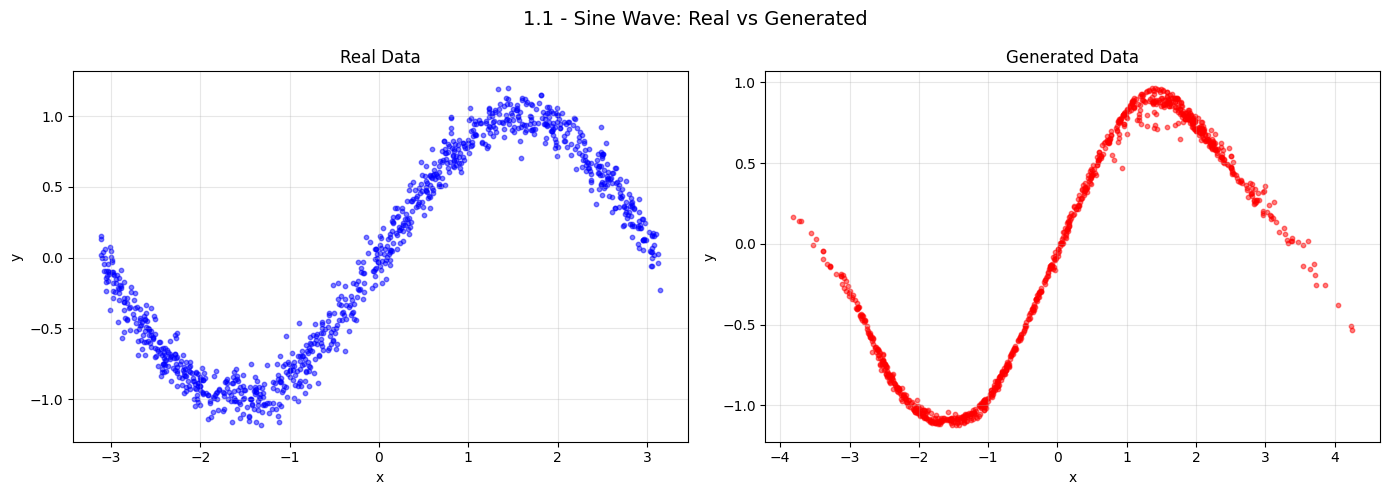

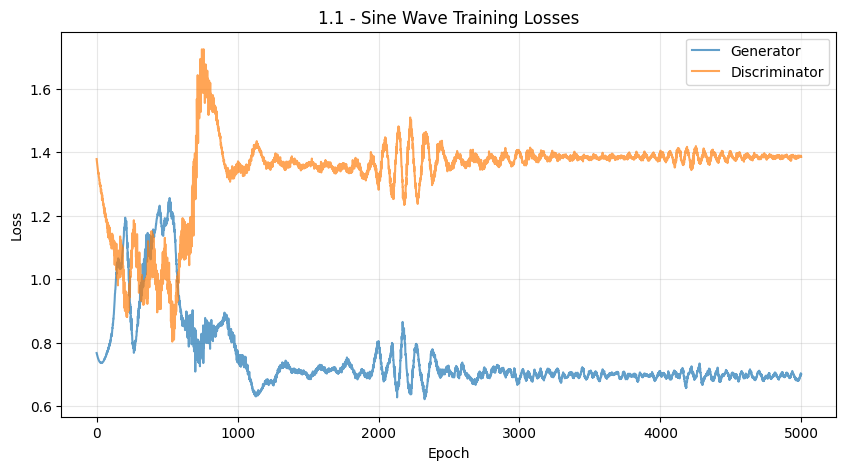

In [63]:
sine_data = generate_sine_data(2000)

G_sine = Generator(z_dim=2, hidden=64, out=2).to(device)
D_sine = Discriminator(inp=2, hidden=64).to(device)

g_l, d_l = train_gan(G_sine, D_sine, sine_data, epochs=5000, z_dim=2)

plot_comparison(sine_data, G_sine, z_dim=2,
                title="1.1 - Sine Wave: Real vs Generated",
                savepath='figures/part1/sine_wave_comparison.png')
plot_losses(g_l, d_l, title="1.1 - Sine Wave Training Losses",
            savepath='figures/part1/sine_wave_losses.png')

## 1.2 - Spiral Distribution GAN

  epoch 1000/8000 | d_loss=1.4297 g_loss=0.6873
  epoch 2000/8000 | d_loss=1.4289 g_loss=0.6665
  epoch 3000/8000 | d_loss=1.3562 g_loss=0.6682
  epoch 4000/8000 | d_loss=1.4267 g_loss=0.7398
  epoch 5000/8000 | d_loss=1.4805 g_loss=0.7888
  epoch 6000/8000 | d_loss=1.3375 g_loss=0.7567
  epoch 7000/8000 | d_loss=1.3559 g_loss=0.6667
  epoch 8000/8000 | d_loss=1.4525 g_loss=0.6686


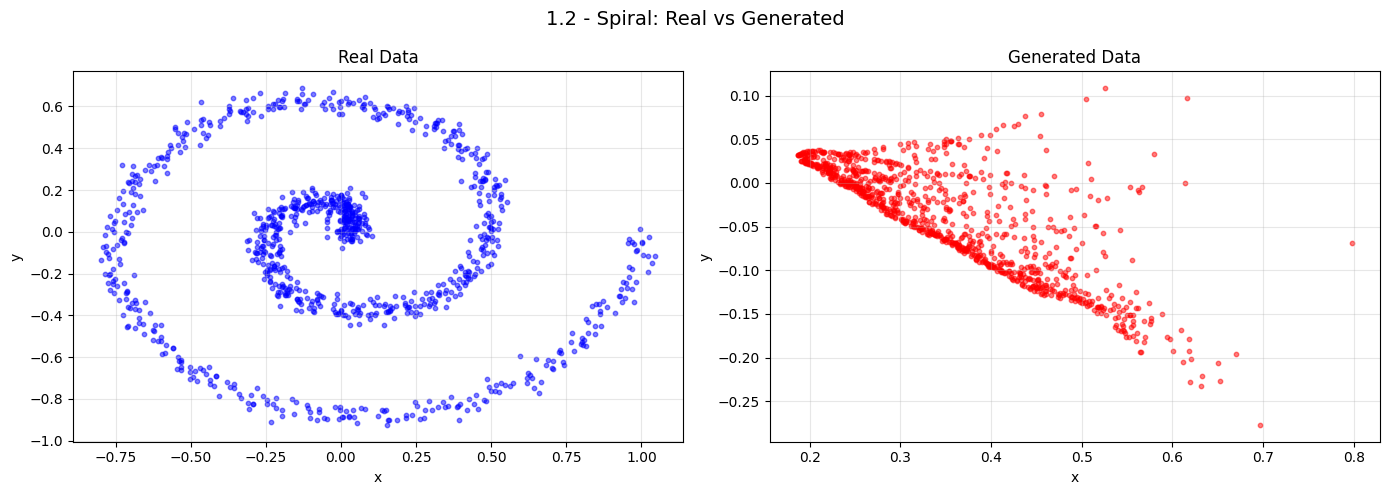

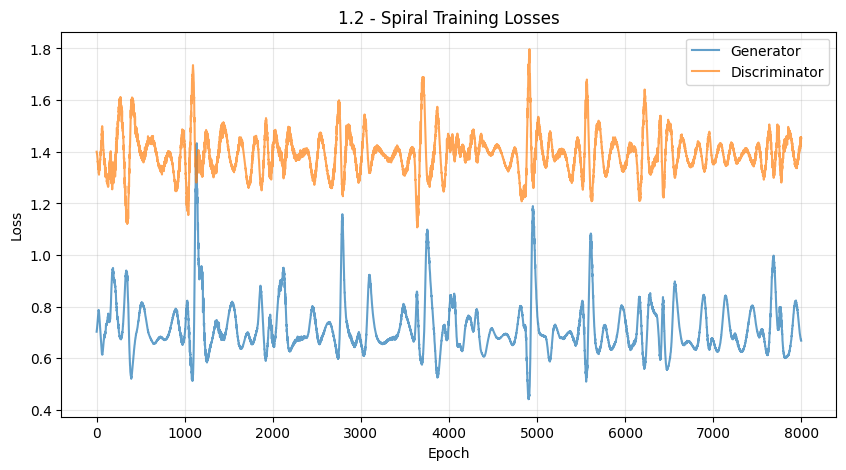

In [64]:
spiral_data = generate_spiral_data(2000, noise=0.03)

G_spiral = Generator(z_dim=2, hidden=128, out=2).to(device)
D_spiral = Discriminator(inp=2, hidden=128).to(device)

g_l2, d_l2 = train_gan(G_spiral, D_spiral, spiral_data, epochs=8000, z_dim=2)

plot_comparison(spiral_data, G_spiral, z_dim=2,
                title="1.2 - Spiral: Real vs Generated",
                savepath='figures/part1/spiral_comparison.png')
plot_losses(g_l2, d_l2, title="1.2 - Spiral Training Losses",
            savepath='figures/part1/spiral_losses.png')

## 1.3 - Architecture Comparison
Comparing original (ReLU, 2 hidden, 64 units) vs modified (ELU + BatchNorm + Dropout, 3 hidden, 128 units)

In [65]:
class GeneratorV2(nn.Module):
    def __init__(self, z_dim=2, hidden=128, out=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, hidden), nn.BatchNorm1d(hidden), nn.ELU(),
            nn.Linear(hidden, hidden), nn.BatchNorm1d(hidden), nn.ELU(),
            nn.Linear(hidden, hidden // 2), nn.BatchNorm1d(hidden // 2), nn.ELU(),
            nn.Linear(hidden // 2, out),
        )
    def forward(self, z):
        return self.net(z)

class DiscriminatorV2(nn.Module):
    def __init__(self, inp=2, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(inp, hidden), nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(hidden, hidden), nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(hidden, hidden // 2), nn.LeakyReLU(0.2),
            nn.Linear(hidden // 2, 1), nn.Sigmoid(),
        )
    def forward(self, x):
        return self.net(x)

In [66]:
print("training original architecture...")
G_orig = Generator(z_dim=2, hidden=64, out=2).to(device)
D_orig = Discriminator(inp=2, hidden=64).to(device)
gl_orig, dl_orig = train_gan(G_orig, D_orig, spiral_data, epochs=8000, z_dim=2)

print("\ntraining modified architecture...")
G_mod = GeneratorV2(z_dim=2, hidden=128, out=2).to(device)
D_mod = DiscriminatorV2(inp=2, hidden=128).to(device)
gl_mod, dl_mod = train_gan(G_mod, D_mod, spiral_data, epochs=8000, z_dim=2)

training original architecture...
  epoch 1000/8000 | d_loss=1.3626 g_loss=0.7373
  epoch 2000/8000 | d_loss=1.4856 g_loss=0.6733
  epoch 3000/8000 | d_loss=1.3863 g_loss=0.6616
  epoch 4000/8000 | d_loss=1.3379 g_loss=0.6998
  epoch 5000/8000 | d_loss=1.4920 g_loss=0.6786
  epoch 6000/8000 | d_loss=1.2740 g_loss=0.7715
  epoch 7000/8000 | d_loss=1.2062 g_loss=0.8199
  epoch 8000/8000 | d_loss=1.4236 g_loss=0.6363

training modified architecture...
  epoch 1000/8000 | d_loss=1.3872 g_loss=0.7050
  epoch 2000/8000 | d_loss=1.3814 g_loss=0.7051
  epoch 3000/8000 | d_loss=1.3858 g_loss=0.7218
  epoch 4000/8000 | d_loss=1.3813 g_loss=0.7097
  epoch 5000/8000 | d_loss=1.3857 g_loss=0.7084
  epoch 6000/8000 | d_loss=1.3905 g_loss=0.6786
  epoch 7000/8000 | d_loss=1.3896 g_loss=0.6848
  epoch 8000/8000 | d_loss=1.3863 g_loss=0.6924


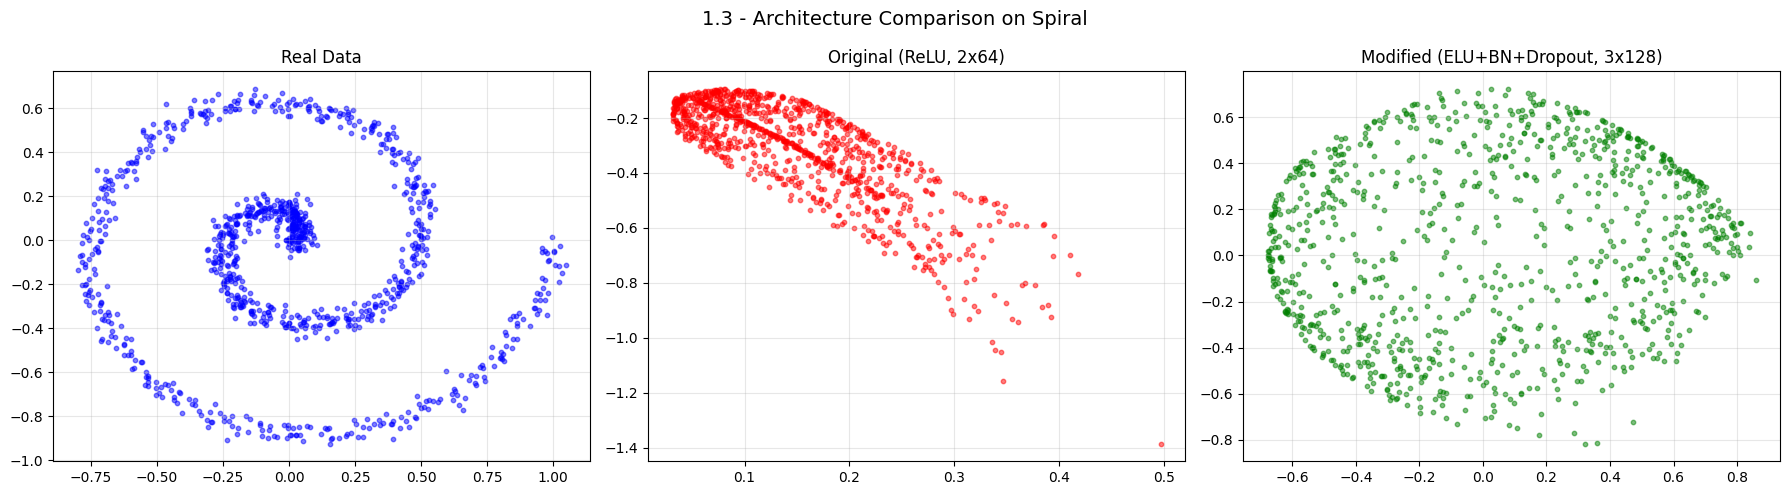

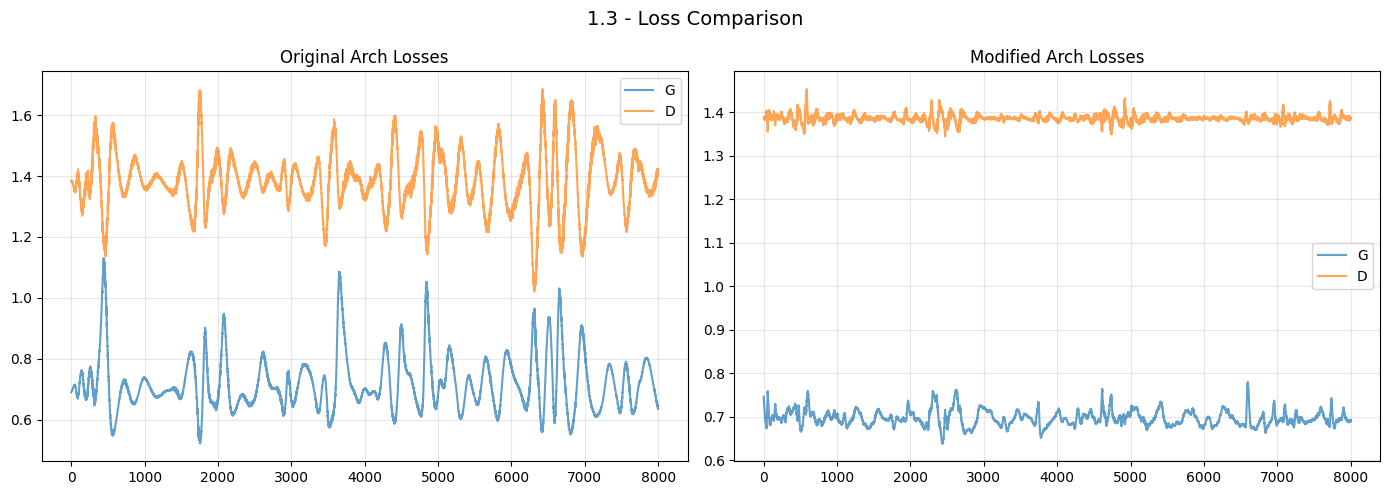

Part 1 done!


In [67]:
G_orig.eval(); G_mod.eval()
with torch.no_grad():
    z = torch.randn(1000, 2, device=device)
    orig_pts = G_orig(z).cpu().numpy()
    mod_pts = G_mod(z).cpu().numpy()
real_np = spiral_data[:1000].numpy()

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))
ax1.scatter(real_np[:,0], real_np[:,1], s=10, alpha=0.5, c='blue')
ax1.set_title('Real Data'); ax1.grid(True, alpha=0.3)
ax2.scatter(orig_pts[:,0], orig_pts[:,1], s=10, alpha=0.5, c='red')
ax2.set_title('Original (ReLU, 2x64)'); ax2.grid(True, alpha=0.3)
ax3.scatter(mod_pts[:,0], mod_pts[:,1], s=10, alpha=0.5, c='green')
ax3.set_title('Modified (ELU+BN+Dropout, 3x128)'); ax3.grid(True, alpha=0.3)
plt.suptitle('1.3 - Architecture Comparison on Spiral', fontsize=14)
plt.tight_layout()
plt.savefig('figures/part1/architecture_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(gl_orig, label='G', alpha=0.7); ax1.plot(dl_orig, label='D', alpha=0.7)
ax1.set_title('Original Arch Losses'); ax1.legend(); ax1.grid(True, alpha=0.3)
ax2.plot(gl_mod, label='G', alpha=0.7); ax2.plot(dl_mod, label='D', alpha=0.7)
ax2.set_title('Modified Arch Losses'); ax2.legend(); ax2.grid(True, alpha=0.3)
plt.suptitle('1.3 - Loss Comparison', fontsize=14)
plt.tight_layout()
plt.savefig('figures/part1/loss_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Part 1 done!")

---
# Part 2.1 - OCTMNIST Retinal Images (DCGAN + cGAN)

### Load and explore OCTMNIST

In [68]:
from medmnist import OCTMNIST

NUM_CLASSES = 4
CLASS_NAMES = ['CNV', 'DME', 'DRUSEN', 'NORMAL']
LATENT_DIM = 100
BATCH_SIZE = 128
NGF = 64
NDF = 64

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5]),
])

train_ds = OCTMNIST(split='train', transform=transform, download=True)
test_ds = OCTMNIST(split='test', transform=transform, download=True)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)
print(f"train: {len(train_ds)} | test: {len(test_ds)}")

train: 97477 | test: 1000


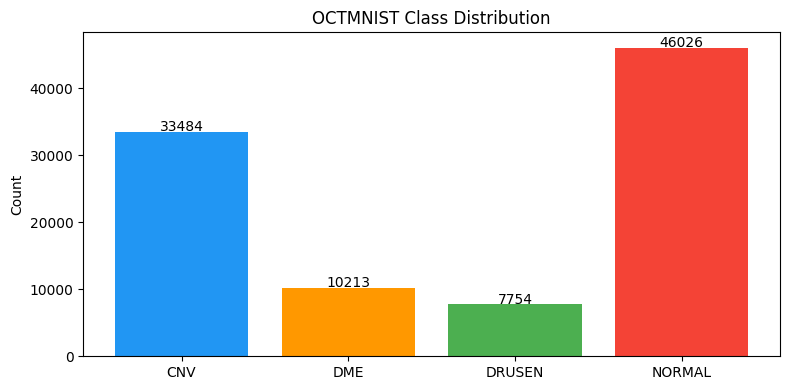

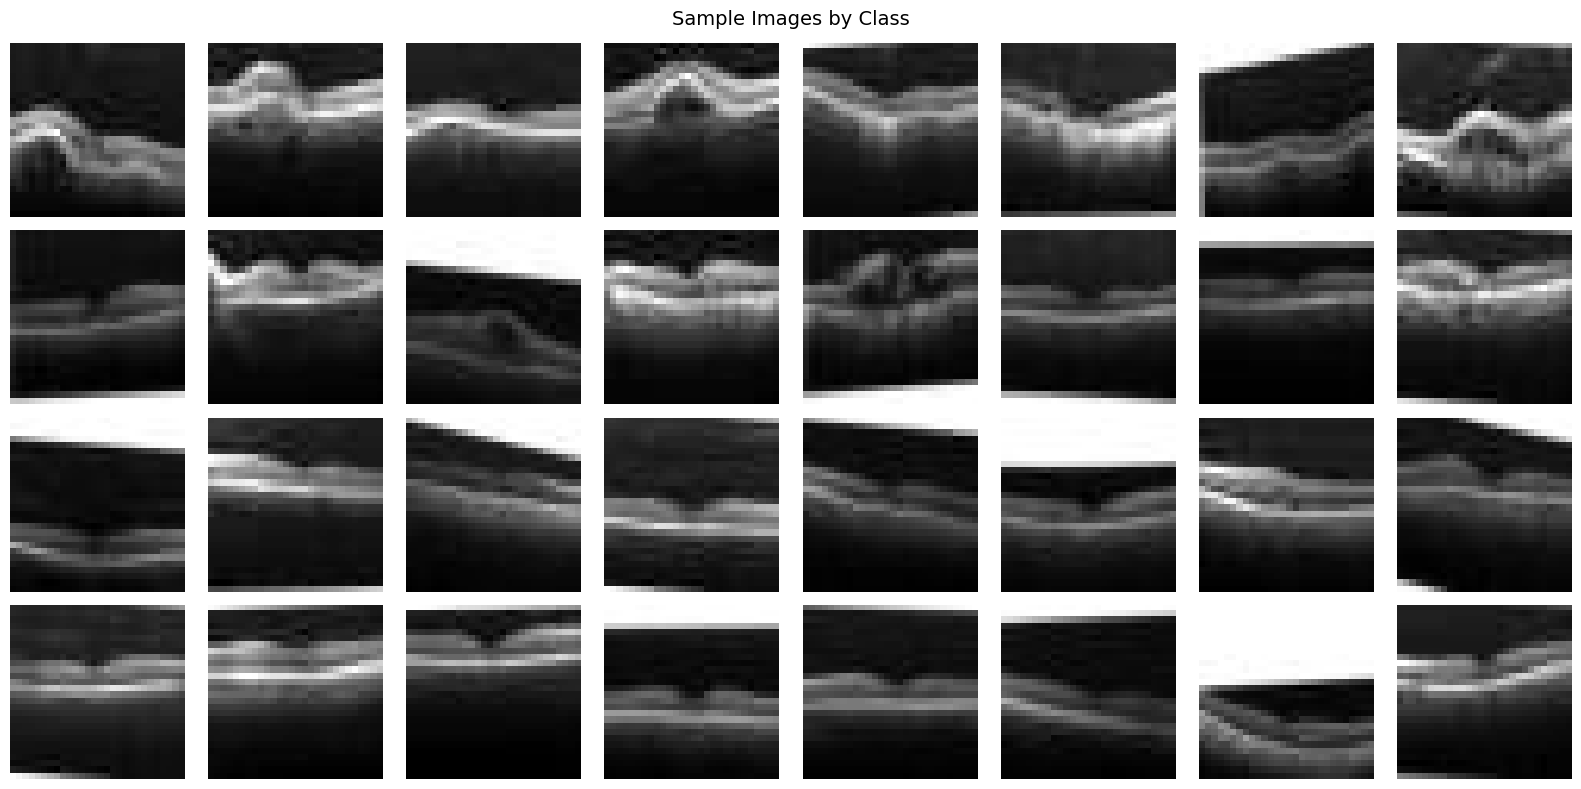

In [69]:
# class distribution
labels = train_ds.labels.flatten()
unique, counts = np.unique(labels, return_counts=True)

plt.figure(figsize=(8, 4))
bars = plt.bar(CLASS_NAMES, counts, color=['#2196F3','#FF9800','#4CAF50','#F44336'])
for b, c in zip(bars, counts):
    plt.text(b.get_x() + b.get_width()/2, c+50, str(c), ha='center')
plt.title('OCTMNIST Class Distribution'); plt.ylabel('Count')
plt.tight_layout()
plt.savefig('figures/part2_1/class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

# sample images
fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for cls in range(4):
    idxs = np.where(labels == cls)[0][:8]
    for j, idx in enumerate(idxs):
        axes[cls][j].imshow(train_ds[idx][0].squeeze().numpy(), cmap='gray')
        axes[cls][j].axis('off')
        if j == 0:
            axes[cls][j].set_ylabel(CLASS_NAMES[cls], rotation=0, labelpad=55, fontsize=11)
plt.suptitle('Sample Images by Class', fontsize=14)
plt.tight_layout()
plt.savefig('figures/part2_1/sample_images.png', dpi=150, bbox_inches='tight')
plt.show()

### DCGAN architecture and training

In [70]:
def init_weights(m):
    name = m.__class__.__name__
    if 'Conv' in name:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif 'BatchNorm' in name:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

class DCGenerator(nn.Module):
    def __init__(self, z_dim=100, ngf=64):
        super().__init__()
        self.ngf = ngf
        self.fc = nn.Sequential(
            nn.Linear(z_dim, ngf*4*7*7),
            nn.BatchNorm1d(ngf*4*7*7), nn.ReLU(True),
        )
        self.conv_layers = nn.Sequential(
            nn.ConvTranspose2d(ngf*4, ngf*2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf*2), nn.ReLU(True),
            nn.ConvTranspose2d(ngf*2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf), nn.ReLU(True),
            nn.Conv2d(ngf, 1, 3, 1, 1, bias=False), nn.Tanh(),
        )
    def forward(self, z):
        x = self.fc(z).view(-1, self.ngf*4, 7, 7)
        return self.conv_layers(x)

class DCDiscriminator(nn.Module):
    def __init__(self, ndf=64):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, ndf, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf, ndf*2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf*2), nn.LeakyReLU(0.2, inplace=True),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(ndf*2*7*7, 1), nn.Sigmoid(),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

In [71]:
G = DCGenerator(z_dim=LATENT_DIM, ngf=NGF).to(device)
D = DCDiscriminator(ndf=NDF).to(device)
G.apply(init_weights); D.apply(init_weights)
print(f"G params: {sum(p.numel() for p in G.parameters()):,}")
print(f"D params: {sum(p.numel() for p in D.parameters()):,}")

criterion = nn.BCELoss()
g_opt = optim.Adam(G.parameters(), lr=0.0002, betas=(0.5, 0.999))
d_opt = optim.Adam(D.parameters(), lr=0.0002, betas=(0.5, 0.999))

fixed_noise = torch.randn(64, LATENT_DIM, device=device)
g_losses, d_losses = [], []
NUM_EPOCHS = 50

for epoch in range(NUM_EPOCHS):
    g_total = d_total = 0.0
    count = 0
    for real_imgs, _ in train_loader:
        bs = real_imgs.size(0)
        real_imgs = real_imgs.to(device)
        ones = torch.ones(bs, 1, device=device)
        zeros = torch.zeros(bs, 1, device=device)

        d_opt.zero_grad()
        z = torch.randn(bs, LATENT_DIM, device=device)
        d_loss = criterion(D(real_imgs), ones) + criterion(D(G(z).detach()), zeros)
        d_loss.backward(); d_opt.step()

        g_opt.zero_grad()
        z = torch.randn(bs, LATENT_DIM, device=device)
        g_loss = criterion(D(G(z)), ones)
        g_loss.backward(); g_opt.step()

        g_total += g_loss.item(); d_total += d_loss.item(); count += 1

    g_losses.append(g_total/count); d_losses.append(d_total/count)
    if (epoch+1) % 10 == 0 or epoch == 0:
        print(f"  epoch {epoch+1}/{NUM_EPOCHS} | d={d_losses[-1]:.4f} g={g_losses[-1]:.4f}")

G params: 1,948,352
D params: 138,625
  epoch 1/50 | d=0.5426 g=2.3901
  epoch 10/50 | d=1.0944 g=1.1845
  epoch 20/50 | d=0.8122 g=1.5993
  epoch 30/50 | d=0.6257 g=1.9934
  epoch 40/50 | d=0.5237 g=2.2084
  epoch 50/50 | d=0.5489 g=2.4092


### DCGAN Results

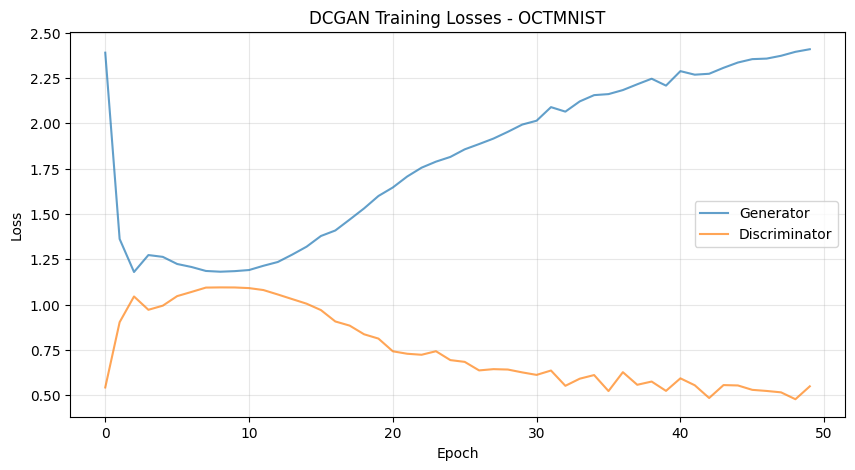

In [72]:
plt.figure(figsize=(10, 5))
plt.plot(g_losses, label='Generator', alpha=0.7)
plt.plot(d_losses, label='Discriminator', alpha=0.7)
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title('DCGAN Training Losses - OCTMNIST')
plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig('figures/part2_1/training_losses.png', dpi=150, bbox_inches='tight')
plt.show()

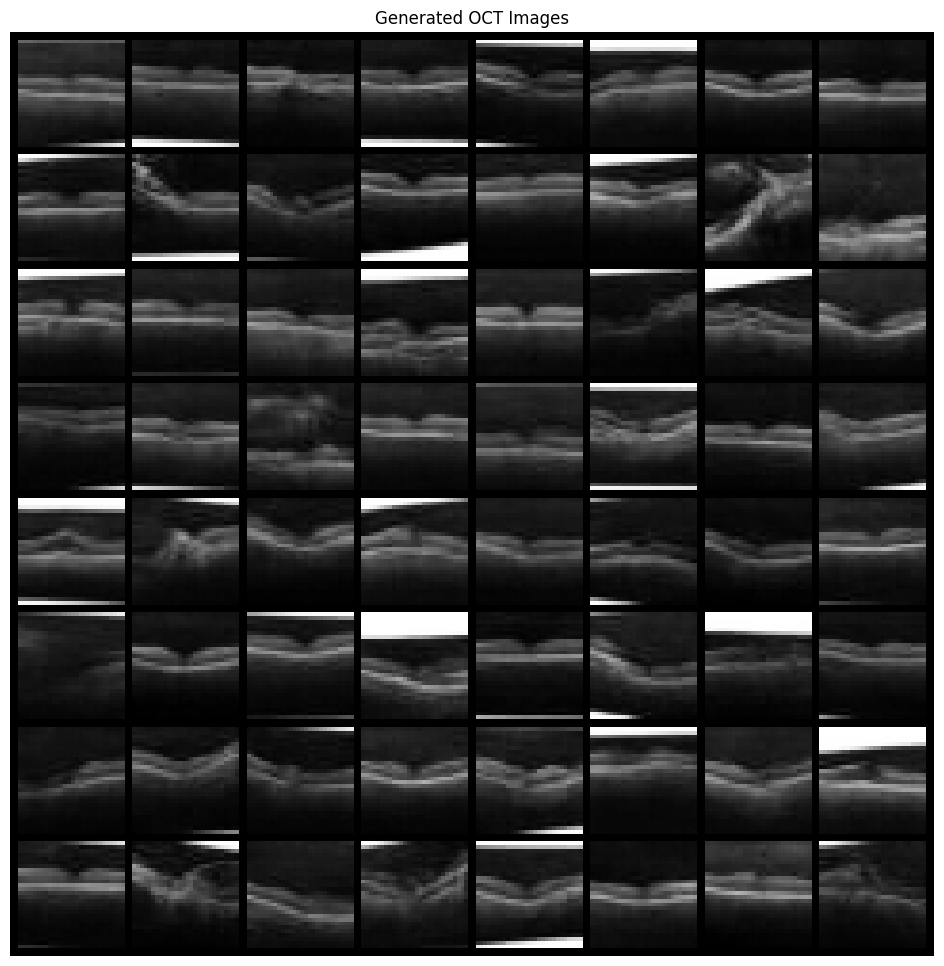

In [73]:
# generated samples grid
G.eval()
with torch.no_grad():
    sample_imgs = G(torch.randn(64, LATENT_DIM, device=device)).cpu()
grid = torchvision.utils.make_grid(sample_imgs, nrow=8, normalize=True, padding=2)
plt.figure(figsize=(12, 12))
plt.imshow(grid.permute(1,2,0).numpy(), cmap='gray')
plt.axis('off'); plt.title('Generated OCT Images')
plt.savefig('figures/part2_1/generated_images.png', dpi=150, bbox_inches='tight')
plt.show()

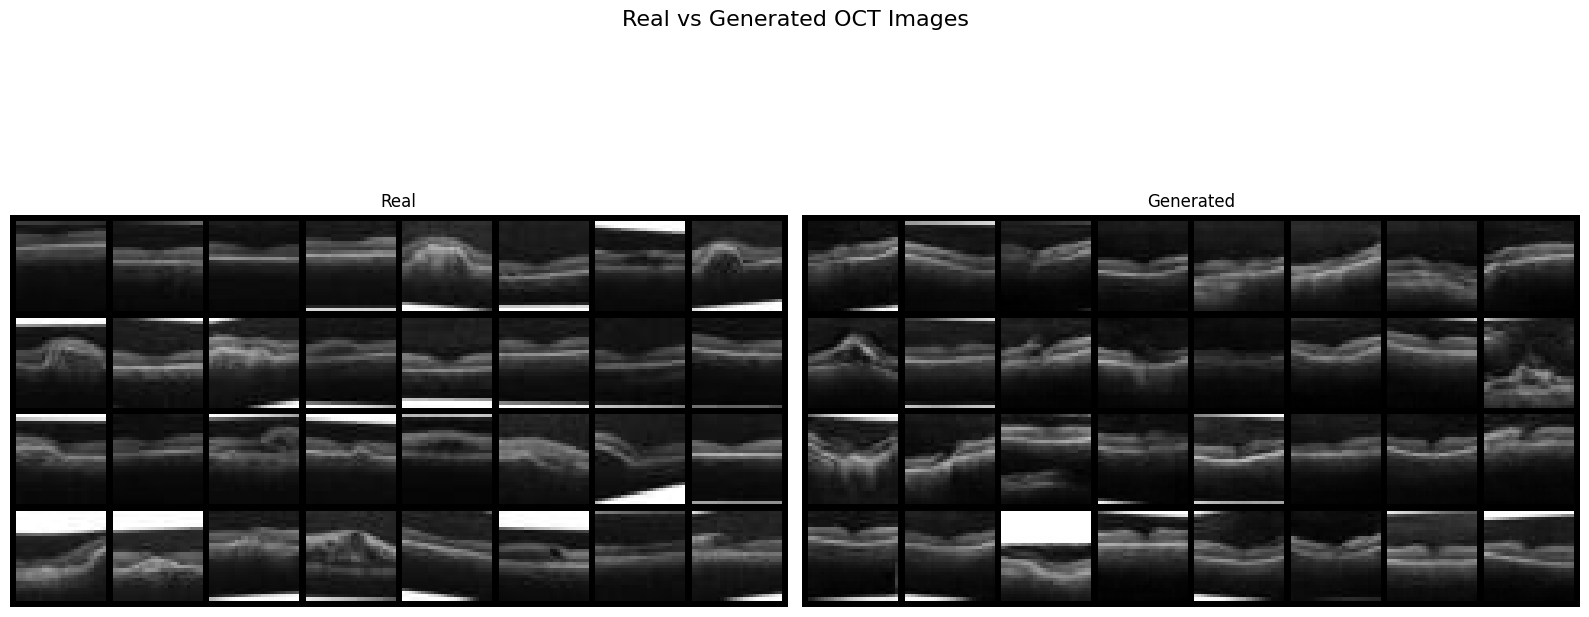

In [74]:
# real vs fake
real_batch, _ = next(iter(test_loader))
real_grid = torchvision.utils.make_grid(real_batch[:32], 8, normalize=True, padding=2)
with torch.no_grad():
    fake_batch = G(torch.randn(32, LATENT_DIM, device=device)).cpu()
fake_grid = torchvision.utils.make_grid(fake_batch, 8, normalize=True, padding=2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
ax1.imshow(real_grid.permute(1,2,0).numpy(), cmap='gray'); ax1.set_title('Real'); ax1.axis('off')
ax2.imshow(fake_grid.permute(1,2,0).numpy(), cmap='gray'); ax2.set_title('Generated'); ax2.axis('off')
plt.suptitle('Real vs Generated OCT Images', fontsize=16)
plt.tight_layout()
plt.savefig('figures/part2_1/real_vs_fake.png', dpi=150, bbox_inches='tight')
plt.show()

### FID Score

In [75]:
def calculate_fid(real_imgs, fake_imgs, bs=32):
    from torchvision.models import inception_v3
    inception = inception_v3(pretrained=True, transform_input=False)
    inception.fc = nn.Identity()
    inception = inception.to(device).eval()

    def prep(imgs):
        imgs = torch.nn.functional.interpolate(imgs, size=299, mode='bilinear', align_corners=False)
        if imgs.shape[1] == 1: imgs = imgs.repeat(1, 3, 1, 1)
        return imgs

    def get_feats(imgs):
        feats = []
        for i in range(0, len(imgs), bs):
            with torch.no_grad():
                feats.append(inception(prep(imgs[i:i+bs]).to(device)).cpu().numpy())
        return np.concatenate(feats)

    print("  extracting features...")
    fr = get_feats(real_imgs)
    ff = get_feats(fake_imgs)
    mu1, sig1 = fr.mean(0), np.cov(fr, rowvar=False)
    mu2, sig2 = ff.mean(0), np.cov(ff, rowvar=False)
    diff = mu1 - mu2
    covmean, _ = linalg.sqrtm(sig1 @ sig2, disp=False)
    if np.iscomplexobj(covmean): covmean = covmean.real
    return float(diff @ diff + np.trace(sig1 + sig2 - 2*covmean))

real_for_fid = torch.cat([b for b, _ in test_loader])[:1000]
with torch.no_grad():
    fake_for_fid = G(torch.randn(1000, LATENT_DIM, device=device)).cpu()
fid = calculate_fid(real_for_fid, fake_for_fid)
print(f"FID score: {fid:.2f}")

  extracting features...
FID score: 40.54


### Extension: Conditional GAN (cGAN)
Feed class labels to both G and D so we can generate specific retinal conditions.

In [76]:
# ---- cGAN setup ----
# clear everything from gpu to free memory
import gc
for obj_name in list(globals()):
    obj = globals()[obj_name]
    if isinstance(obj, torch.nn.Module):
        try:
            obj.cpu()
        except:
            pass
gc.collect()
torch.cuda.empty_cache()
print(f"GPU memory freed. Device: {device}")

# reload the dataset fresh for cGAN
transform_cgan = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5]),
])
from medmnist import OCTMNIST
train_ds_cgan = OCTMNIST(split='train', transform=transform_cgan, download=True)
train_loader_cgan = DataLoader(train_ds_cgan, batch_size=64, shuffle=True, drop_last=True)
print(f"reloaded train data: {len(train_ds_cgan)} samples (batch_size=64)")

class CondGenerator(nn.Module):
    def __init__(self, z_dim=100, n_classes=4, embed_dim=10, ngf=64):
        super().__init__()
        self.ngf = ngf
        self.label_emb = nn.Embedding(n_classes, embed_dim)
        self.fc = nn.Sequential(
            nn.Linear(z_dim + embed_dim, ngf*4*7*7),
            nn.BatchNorm1d(ngf*4*7*7), nn.ReLU(True),
        )
        self.conv = nn.Sequential(
            nn.ConvTranspose2d(ngf*4, ngf*2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf*2), nn.ReLU(True),
            nn.ConvTranspose2d(ngf*2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf), nn.ReLU(True),
            nn.Conv2d(ngf, 1, 3, 1, 1, bias=False), nn.Tanh(),
        )
    def forward(self, z, labels):
        emb = self.label_emb(labels)
        x = torch.cat([z, emb], dim=1)
        x = self.fc(x).view(-1, self.ngf*4, 7, 7)
        return self.conv(x)

class CondDiscriminator(nn.Module):
    def __init__(self, n_classes=4, ndf=64, img_size=28):
        super().__init__()
        self.img_size = img_size
        self.label_emb = nn.Embedding(n_classes, img_size * img_size)
        self.features = nn.Sequential(
            nn.Conv2d(2, ndf, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf, ndf*2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf*2), nn.LeakyReLU(0.2, inplace=True),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(ndf*2*7*7, 1), nn.Sigmoid(),
        )
    def forward(self, imgs, labels):
        label_map = self.label_emb(labels).view(-1, 1, self.img_size, self.img_size)
        x = torch.cat([imgs, label_map], dim=1)
        return self.classifier(self.features(x))

print("cGAN models defined")

GPU memory freed. Device: cuda
reloaded train data: 97477 samples (batch_size=64)
cGAN models defined


In [77]:
# train the cGAN (using smaller batch size to avoid memory issues)
LATENT_DIM = 100
NUM_CLASSES = 4
CLASS_NAMES = ['CNV', 'DME', 'DRUSEN', 'NORMAL']

cG = CondGenerator(z_dim=LATENT_DIM, n_classes=NUM_CLASSES, embed_dim=10, ngf=64).to(device)
cD = CondDiscriminator(n_classes=NUM_CLASSES, ndf=64, img_size=28).to(device)
cG.apply(init_weights)
cD.apply(init_weights)

cgan_criterion = nn.BCELoss()
cg_opt = optim.Adam(cG.parameters(), lr=0.0002, betas=(0.5, 0.999))
cd_opt = optim.Adam(cD.parameters(), lr=0.0002, betas=(0.5, 0.999))

cg_losses = []
cd_losses = []
CGAN_EPOCHS = 50

print("training cGAN...")
for epoch in range(CGAN_EPOCHS):
    g_total = 0.0
    d_total = 0.0
    count = 0

    for imgs, labs in train_loader_cgan:
        bs = imgs.size(0)
        imgs = imgs.to(device)
        labs = labs.squeeze().long().to(device)
        ones = torch.ones(bs, 1, device=device)
        zeros = torch.zeros(bs, 1, device=device)

        # discriminator
        cd_opt.zero_grad()
        fake_labels = torch.randint(0, NUM_CLASSES, (bs,), device=device)
        z = torch.randn(bs, LATENT_DIM, device=device)
        fake_imgs = cG(z, fake_labels)
        d_loss = cgan_criterion(cD(imgs, labs), ones) + cgan_criterion(cD(fake_imgs.detach(), fake_labels), zeros)
        d_loss.backward()
        cd_opt.step()

        # generator
        cg_opt.zero_grad()
        fake_labels = torch.randint(0, NUM_CLASSES, (bs,), device=device)
        z = torch.randn(bs, LATENT_DIM, device=device)
        fake_imgs = cG(z, fake_labels)
        g_loss = cgan_criterion(cD(fake_imgs, fake_labels), ones)
        g_loss.backward()
        cg_opt.step()

        g_total += g_loss.item()
        d_total += d_loss.item()
        count += 1

    cg_losses.append(g_total / count)
    cd_losses.append(d_total / count)

    if (epoch+1) % 10 == 0:
        print(f"  cGAN epoch {epoch+1}/{CGAN_EPOCHS} | d={cd_losses[-1]:.4f} g={cg_losses[-1]:.4f}")

print("cGAN training done!")

training cGAN...
  cGAN epoch 10/50 | d=0.0326 g=17.6901
  cGAN epoch 20/50 | d=0.0273 g=19.4653
  cGAN epoch 30/50 | d=0.0134 g=20.7190
  cGAN epoch 40/50 | d=0.0194 g=22.9109
  cGAN epoch 50/50 | d=0.0127 g=23.5267
cGAN training done!


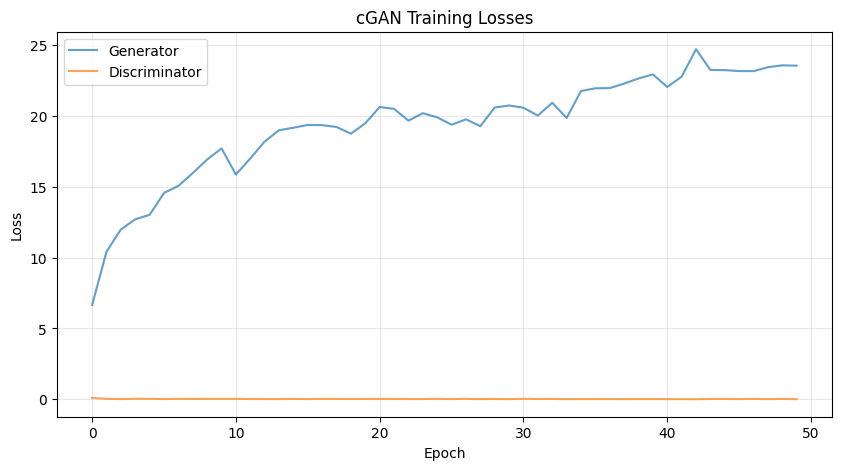

In [78]:
# cGAN training losses
plt.figure(figsize=(10, 5))
plt.plot(cg_losses, label='Generator', alpha=0.7)
plt.plot(cd_losses, label='Discriminator', alpha=0.7)
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title('cGAN Training Losses'); plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig('figures/part2_1/cgan_losses.png', dpi=150, bbox_inches='tight')
plt.show()

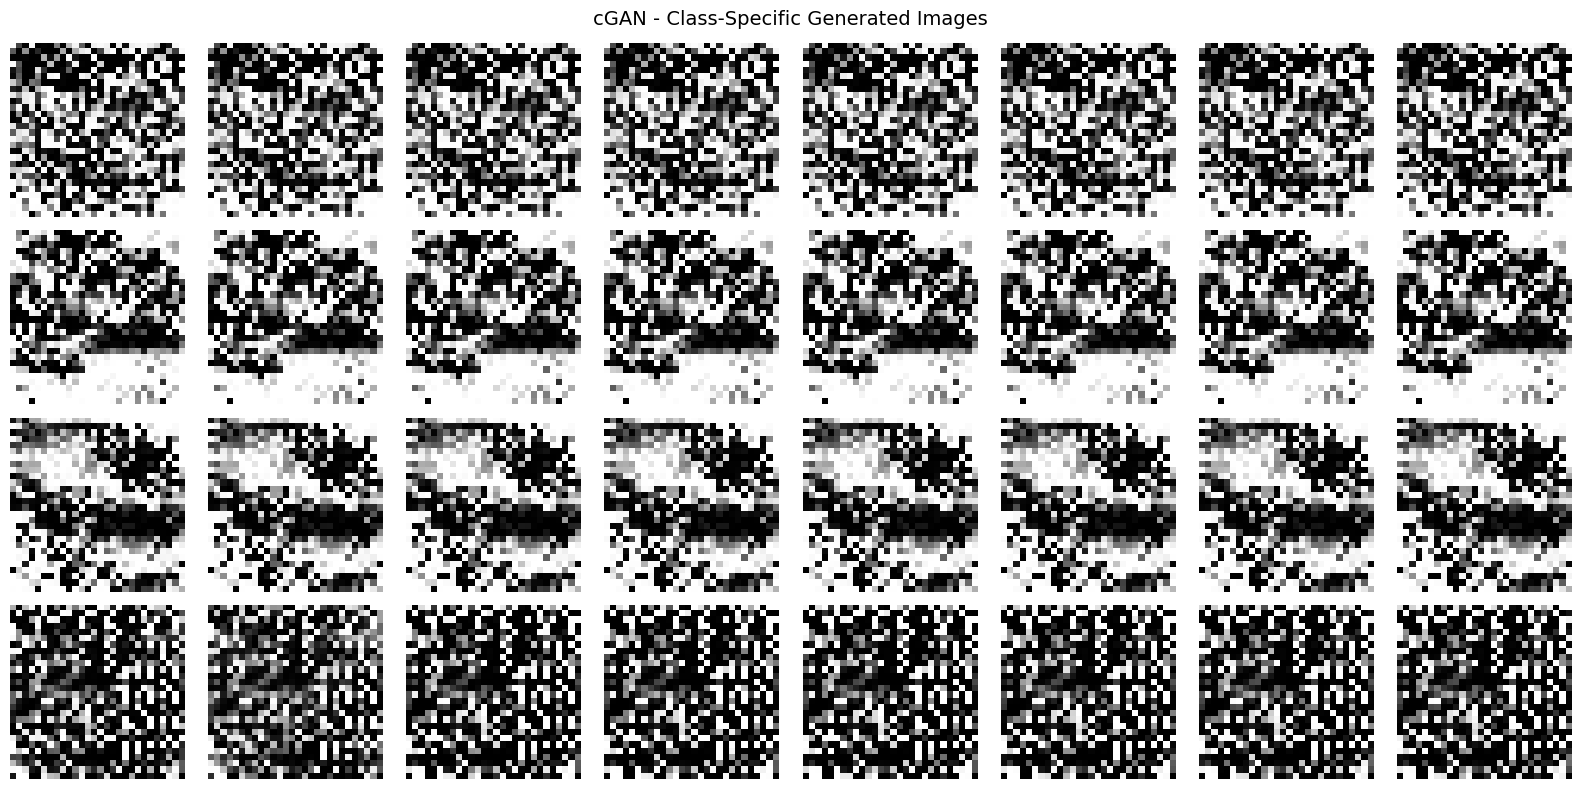

Part 2.1 done!


In [79]:
# generate class-specific images
cG.eval()
fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for cls in range(4):
    z = torch.randn(8, LATENT_DIM, device=device)
    labs = torch.full((8,), cls, dtype=torch.long, device=device)
    with torch.no_grad():
        imgs = cG(z, labs).cpu()
    for j in range(8):
        axes[cls][j].imshow(imgs[j].squeeze().numpy(), cmap='gray')
        axes[cls][j].axis('off')
        if j == 0:
            axes[cls][j].set_ylabel(CLASS_NAMES[cls], rotation=0, labelpad=50, fontsize=11)

plt.suptitle('cGAN - Class-Specific Generated Images', fontsize=14)
plt.tight_layout()
plt.savefig('figures/part2_1/cgan_class_samples.png', dpi=150, bbox_inches='tight')
plt.show()
print("Part 2.1 done!")

---
# Part 2.2 - CICIDS 2017 Synthetic Traffic (Tabular GAN)

Download the dataset from Kaggle: https://www.kaggle.com/datasets/chethuhn/network-intrusion-dataset

### Upload CICIDS dataset

### Load and preprocess

In [80]:
import os
for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/ravik48149/archive/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
/kaggle/input/datasets/ravik48149/archive/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
/kaggle/input/datasets/ravik48149/archive/Tuesday-WorkingHours.pcap_ISCX.csv
/kaggle/input/datasets/ravik48149/archive/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
/kaggle/input/datasets/ravik48149/archive/Monday-WorkingHours.pcap_ISCX.csv
/kaggle/input/datasets/ravik48149/archive/Friday-WorkingHours-Morning.pcap_ISCX.csv
/kaggle/input/datasets/ravik48149/archive/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
/kaggle/input/datasets/ravik48149/archive/Wednesday-workingHours.pcap_ISCX.csv


In [81]:
import glob

DATA_DIR ='/kaggle/input/datasets/ravik48149/archive'

def load_wednesday(data_dir):
    filepath = None
    for pattern in ['Wednesday*', 'wednesday*', '*Wednesday*', '*workingHours*Wednesday*']:
        matches = glob.glob(os.path.join(data_dir, pattern))
        if matches:
            filepath = matches[0]
            break
    if not filepath:
        # try listing all files and picking the wednesday one
        all_files = os.listdir(data_dir)
        for f in all_files:
            if 'wednesday' in f.lower():
                filepath = os.path.join(data_dir, f)
                break
    if not filepath:
        raise FileNotFoundError(f"cant find Wednesday CSV in {data_dir}. Files found: {os.listdir(data_dir)}")

    print(f"loading {filepath}...")
    df = pd.read_csv(filepath, encoding='utf-8', low_memory=False)
    df.columns = df.columns.str.strip()
    print(f"shape: {df.shape}")
    print(f"\nlabel counts:\n{df['Label'].value_counts()}")
    return df

def clean_data(df):
    labels = df['Label'].values
    feats = df.drop(columns=['Label']).select_dtypes(include=[np.number])
    feats = feats.replace([np.inf, -np.inf], np.nan)
    feats = feats.dropna(axis=1, how='all')
    valid = ~feats.isna().any(axis=1)
    feats = feats[valid]
    labels = labels[valid.values]
    print(f"after cleaning: {feats.shape[0]} rows, {feats.shape[1]} features")
    for lbl, cnt in zip(*np.unique(labels, return_counts=True)):
        print(f"  {lbl}: {cnt}")
    scaler = StandardScaler()
    X = scaler.fit_transform(feats.values)
    return X, labels, scaler, feats.columns.tolist()

df = load_wednesday(DATA_DIR)
X, labels_cicids, scaler, feat_names = clean_data(df)
n_features = X.shape[1]

loading /kaggle/input/datasets/ravik48149/archive/Wednesday-workingHours.pcap_ISCX.csv...
shape: (692703, 79)

label counts:
Label
BENIGN              440031
DoS Hulk            231073
DoS GoldenEye        10293
DoS slowloris         5796
DoS Slowhttptest      5499
Heartbleed              11
Name: count, dtype: int64
after cleaning: 691406 rows, 78 features
  BENIGN: 439683
  DoS GoldenEye: 10293
  DoS Hulk: 230124
  DoS Slowhttptest: 5499
  DoS slowloris: 5796
  Heartbleed: 11


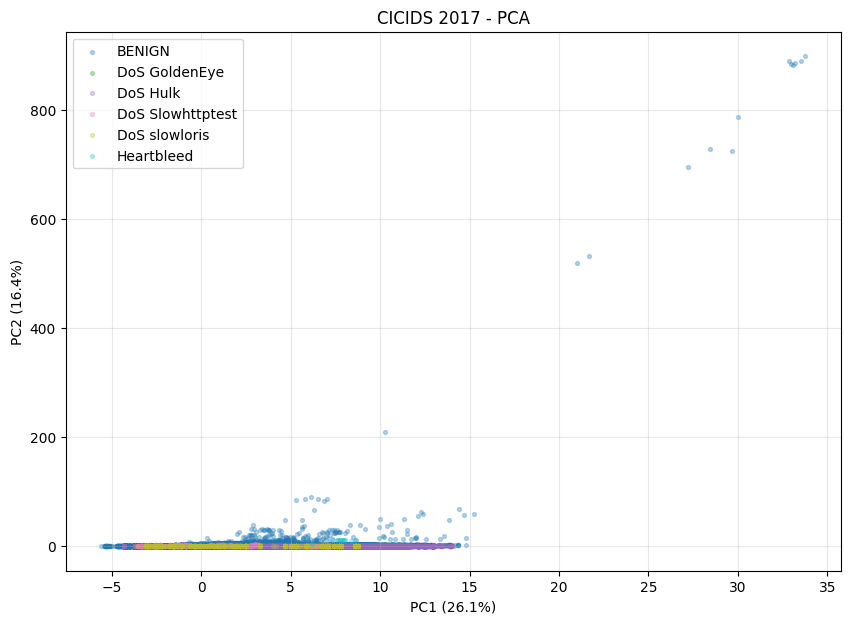

In [82]:
# PCA exploration
pca = PCA(n_components=2)
Z = pca.fit_transform(X)
ulabels = np.unique(labels_cicids)
colors = plt.cm.tab10(np.linspace(0, 1, len(ulabels)))

plt.figure(figsize=(10, 7))
for i, lbl in enumerate(ulabels):
    mask = labels_cicids == lbl
    plt.scatter(Z[mask, 0], Z[mask, 1], s=8, alpha=0.3, c=[colors[i]], label=lbl)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
plt.title('CICIDS 2017 - PCA'); plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig('figures/part2_2/exploration_pca.png', dpi=150, bbox_inches='tight')
plt.show()

### Tabular GAN

In [83]:
class TabGenerator(nn.Module):
    def __init__(self, z_dim, hidden, out_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, hidden), nn.BatchNorm1d(hidden), nn.ReLU(),
            nn.Linear(hidden, hidden*2), nn.BatchNorm1d(hidden*2), nn.ReLU(),
            nn.Linear(hidden*2, hidden), nn.BatchNorm1d(hidden), nn.ReLU(),
            nn.Linear(hidden, out_dim),
        )
    def forward(self, z):
        return self.net(z)

class TabDiscriminator(nn.Module):
    def __init__(self, in_dim, hidden):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(hidden, hidden*2), nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(hidden*2, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, 1), nn.Sigmoid(),
        )
    def forward(self, x):
        return self.net(x)

In [84]:
Z_DIM = 64
HIDDEN = 256
BS_TAB = 512
TAB_EPOCHS = 500

tG = TabGenerator(Z_DIM, HIDDEN, n_features).to(device)
tD = TabDiscriminator(n_features, HIDDEN).to(device)
print(f"G params: {sum(p.numel() for p in tG.parameters()):,}")
print(f"D params: {sum(p.numel() for p in tD.parameters()):,}")

real_tensor = torch.FloatTensor(X)
tab_criterion = nn.BCELoss()
tg_opt = optim.Adam(tG.parameters(), lr=0.0002, betas=(0.5, 0.999))
td_opt = optim.Adam(tD.parameters(), lr=0.0002, betas=(0.5, 0.999))

tg_losses, td_losses = [], []
N = len(real_tensor)

print("training tabular GAN...")
for epoch in range(TAB_EPOCHS):
    perm = torch.randperm(N)
    g_total = d_total = 0.0
    nbatch = 0
    for i in range(0, N, BS_TAB):
        idx = perm[i:i+BS_TAB]
        if len(idx) < BS_TAB:
            continue
        real_batch = real_tensor[idx].to(device)
        ones = torch.ones(BS_TAB, 1, device=device)
        zeros = torch.zeros(BS_TAB, 1, device=device)

        td_opt.zero_grad()
        z = torch.randn(BS_TAB, Z_DIM, device=device)
        d_loss = tab_criterion(tD(real_batch), ones) + tab_criterion(tD(tG(z).detach()), zeros)
        d_loss.backward(); td_opt.step()

        tg_opt.zero_grad()
        z = torch.randn(BS_TAB, Z_DIM, device=device)
        g_loss = tab_criterion(tD(tG(z)), ones)
        g_loss.backward(); tg_opt.step()

        g_total += g_loss.item(); d_total += d_loss.item(); nbatch += 1

    if nbatch > 0:
        tg_losses.append(g_total/nbatch)
        td_losses.append(d_total/nbatch)
    if (epoch+1) % 100 == 0:
        print(f"  epoch {epoch+1}/{TAB_EPOCHS} | d={td_losses[-1]:.4f} g={tg_losses[-1]:.4f}")

G params: 301,646
D params: 283,393
training tabular GAN...
  epoch 100/500 | d=0.4951 g=3.8249
  epoch 200/500 | d=0.2599 g=6.1241
  epoch 300/500 | d=0.2041 g=6.7696
  epoch 400/500 | d=0.2794 g=5.4199
  epoch 500/500 | d=0.3130 g=5.5155


### Evaluation

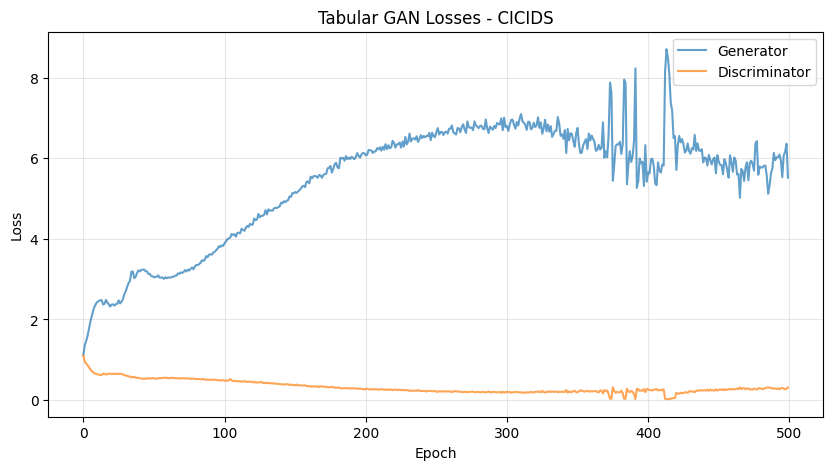

In [85]:
plt.figure(figsize=(10, 5))
plt.plot(tg_losses, label='Generator', alpha=0.7)
plt.plot(td_losses, label='Discriminator', alpha=0.7)
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title('Tabular GAN Losses - CICIDS'); plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig('figures/part2_2/training_losses.png', dpi=150, bbox_inches='tight')
plt.show()

tG.eval()
with torch.no_grad():
    fake_data = tG(torch.randn(5000, Z_DIM, device=device)).cpu().numpy()

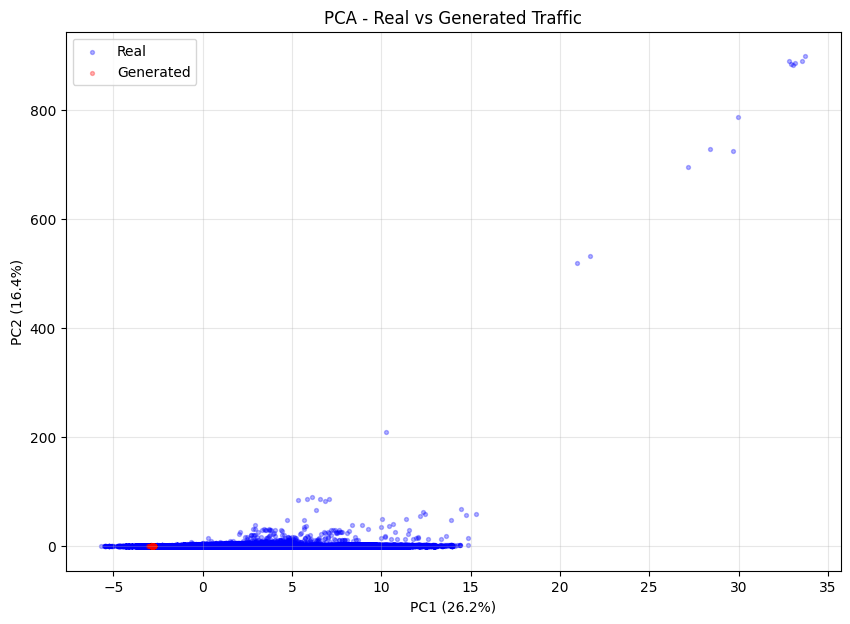

In [86]:
# PCA comparison
pca2 = PCA(n_components=2)
combined = np.vstack([X, fake_data])
Z2 = pca2.fit_transform(combined)
n = len(X)

plt.figure(figsize=(10, 7))
plt.scatter(Z2[:n, 0], Z2[:n, 1], s=8, alpha=0.3, c='blue', label='Real')
plt.scatter(Z2[n:, 0], Z2[n:, 1], s=8, alpha=0.3, c='red', label='Generated')
plt.xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]:.1%})')
plt.ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]:.1%})')
plt.title('PCA - Real vs Generated Traffic'); plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig('figures/part2_2/pca_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

running t-SNE...


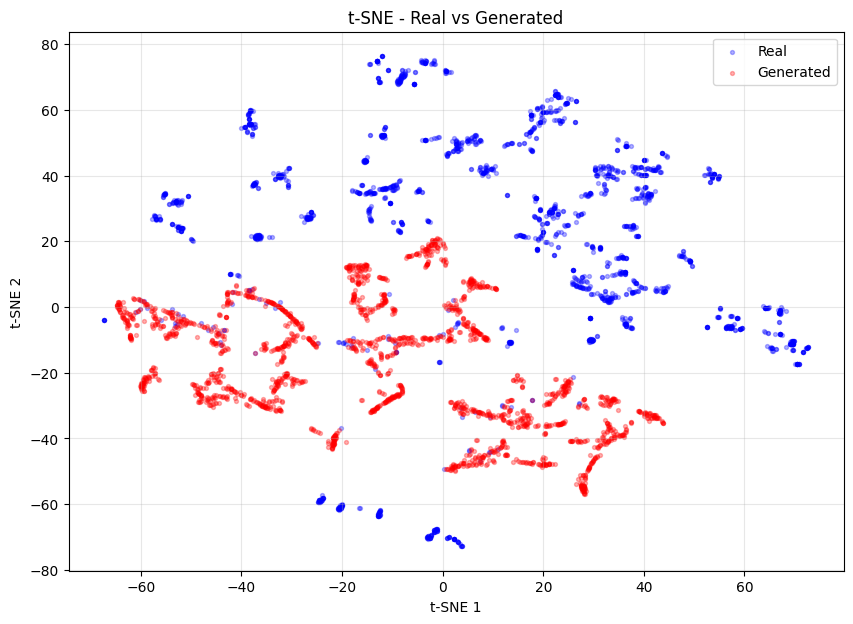

In [87]:
# t-SNE comparison
r_sub = X[:2000]; f_sub = fake_data[:2000]
combined_tsne = np.vstack([r_sub, f_sub])
print("running t-SNE...")
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
Z_tsne = tsne.fit_transform(combined_tsne)
n_r = len(r_sub)

plt.figure(figsize=(10, 7))
plt.scatter(Z_tsne[:n_r, 0], Z_tsne[:n_r, 1], s=8, alpha=0.3, c='blue', label='Real')
plt.scatter(Z_tsne[n_r:, 0], Z_tsne[n_r:, 1], s=8, alpha=0.3, c='red', label='Generated')
plt.xlabel('t-SNE 1'); plt.ylabel('t-SNE 2')
plt.title('t-SNE - Real vs Generated'); plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig('figures/part2_2/tsne_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

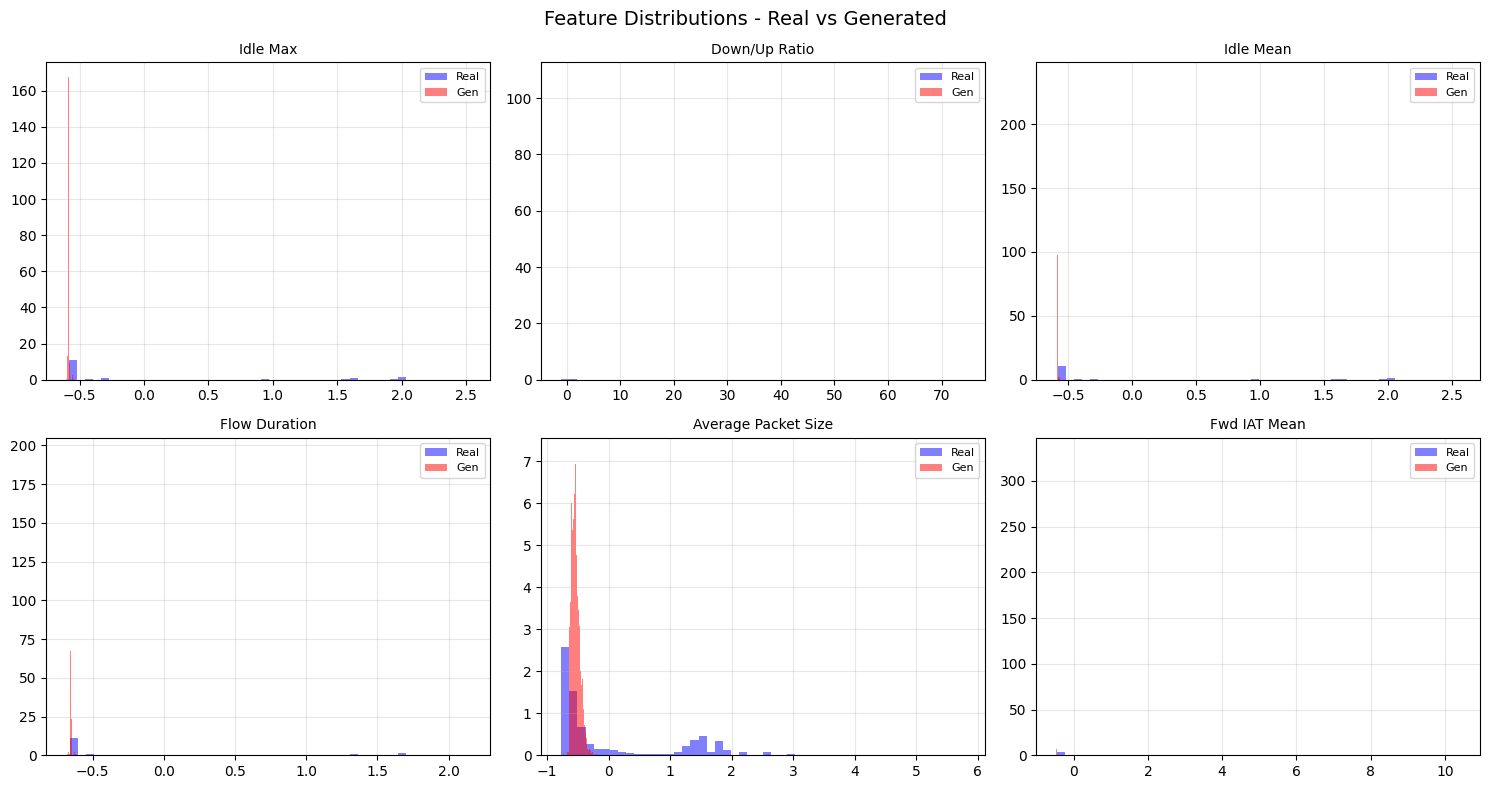

mean MAE (means): 0.2940
mean MAE (stds):  0.8343
correlation:      0.1533

Part 2.2 done!


In [88]:
# feature distributions
variances = np.var(X, axis=0)
top_idx = np.argsort(variances)[-6:]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, idx in zip(axes.flat, top_idx):
    ax.hist(X[:, idx], bins=50, alpha=0.5, density=True, color='blue', label='Real')
    ax.hist(fake_data[:, idx], bins=50, alpha=0.5, density=True, color='red', label='Gen')
    ax.set_title(feat_names[idx][:25], fontsize=10); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
plt.suptitle('Feature Distributions - Real vs Generated', fontsize=14)
plt.tight_layout()
plt.savefig('figures/part2_2/feature_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

mae_means = np.mean(np.abs(X.mean(0) - fake_data.mean(0)))
mae_stds = np.mean(np.abs(X.std(0) - fake_data.std(0)))
corr = np.corrcoef(X.mean(0), fake_data.mean(0))[0, 1]
print(f"mean MAE (means): {mae_means:.4f}")
print(f"mean MAE (stds):  {mae_stds:.4f}")
print(f"correlation:      {corr:.4f}")
print("\nPart 2.2 done!")

---
# Part 2.3 - QuickDraw Birthday Cake (DCGAN)
Extension: train on cat, house, tree as well

### Download and explore

In [89]:
def download_quickdraw(category='birthday cake', save_dir='data/quickdraw'):
    os.makedirs(save_dir, exist_ok=True)
    safe = category.replace(' ', '_')
    local = os.path.join(save_dir, f'{safe}.npy')
    if not os.path.exists(local):
        url_cat = category.replace(' ', '%20')
        url = f'https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/{url_cat}.npy'
        print(f"downloading '{category}'...")
        r = requests.get(url)
        r.raise_for_status()
        with open(local, 'wb') as f: f.write(r.content)
    data = np.load(local)
    print(f"loaded '{category}': {data.shape[0]} images (28x28)")
    return data

def make_dataloader(data, bs=128, max_n=50000):
    if len(data) > max_n:
        data = data[np.random.choice(len(data), max_n, replace=False)]
    imgs = data.astype(np.float32) / 255.0
    imgs = (imgs - 0.5) / 0.5
    tensor = torch.FloatTensor(imgs.reshape(-1, 1, 28, 28))
    return DataLoader(TensorDataset(tensor), batch_size=bs, shuffle=True, drop_last=True)

raw = download_quickdraw('birthday cake')

downloading 'birthday cake'...
loaded 'birthday cake': 144982 images (28x28)


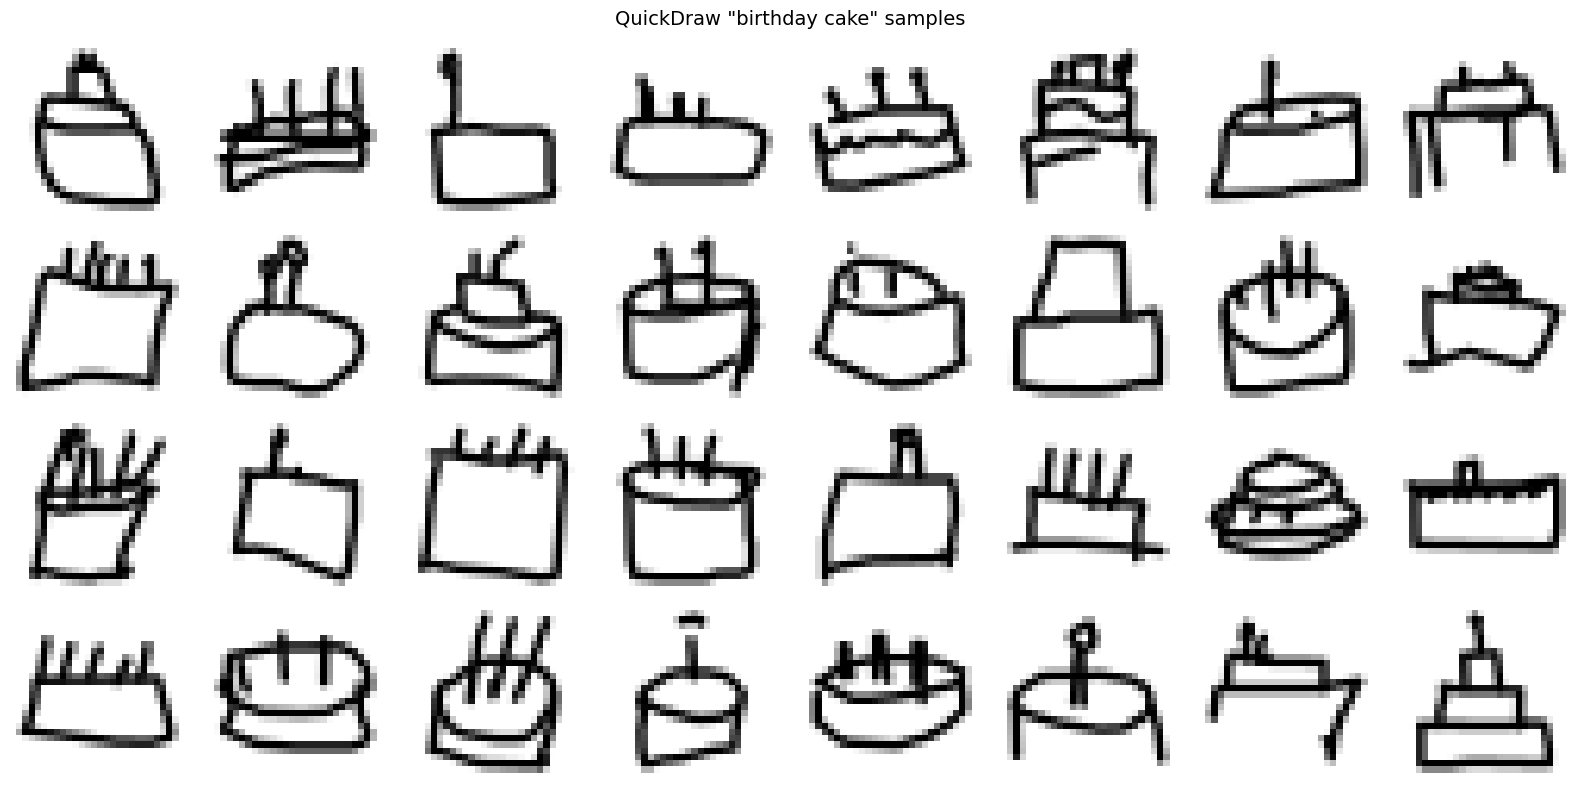

In [90]:
fig, axes = plt.subplots(4, 8, figsize=(16, 8))
idxs = np.random.choice(len(raw), 32, replace=False)
for i, idx in enumerate(idxs):
    r, c = divmod(i, 8)
    axes[r][c].imshow(255 - raw[idx].reshape(28, 28), cmap='gray')
    axes[r][c].axis('off')
plt.suptitle('QuickDraw "birthday cake" samples', fontsize=14)
plt.tight_layout()
plt.savefig('figures/part2_3/sample_sketches.png', dpi=150, bbox_inches='tight')
plt.show()

### DCGAN for sketches

In [91]:
class SketchGenerator(nn.Module):
    def __init__(self, z_dim=100, ngf=64):
        super().__init__()
        self.ngf = ngf
        self.project = nn.Sequential(
            nn.Linear(z_dim, ngf*4*7*7), nn.BatchNorm1d(ngf*4*7*7), nn.ReLU(True),
        )
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(ngf*4, ngf*2, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf*2), nn.ReLU(True),
            nn.ConvTranspose2d(ngf*2, ngf, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf), nn.ReLU(True),
            nn.Conv2d(ngf, 1, 3, 1, 1, bias=False), nn.Tanh(),
        )
    def forward(self, z):
        return self.deconv(self.project(z).view(-1, self.ngf*4, 7, 7))

class SketchDiscriminator(nn.Module):
    def __init__(self, ndf=64):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, ndf, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf, ndf*2, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf*2), nn.LeakyReLU(0.2, inplace=True),
        )
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(ndf*2*7*7, 1), nn.Sigmoid())
    def forward(self, x):
        return self.head(self.conv(x))

### Train

In [92]:
cake_loader = make_dataloader(raw)

sG = SketchGenerator(LATENT_DIM, NGF).to(device)
sD = SketchDiscriminator(NDF).to(device)
sG.apply(init_weights); sD.apply(init_weights)
print(f"G params: {sum(p.numel() for p in sG.parameters()):,}")
print(f"D params: {sum(p.numel() for p in sD.parameters()):,}")

sketch_crit = nn.BCELoss()
sg_opt = optim.Adam(sG.parameters(), lr=0.0002, betas=(0.5, 0.999))
sd_opt = optim.Adam(sD.parameters(), lr=0.0002, betas=(0.5, 0.999))

fixed_z = torch.randn(64, LATENT_DIM, device=device)
sg_losses, sd_losses = [], []
sketch_snaps = []
SKETCH_EPOCHS = 50

print("training sketch DCGAN...")
for epoch in range(SKETCH_EPOCHS):
    g_total = d_total = 0.0; count = 0
    for (real_imgs,) in cake_loader:
        bs = real_imgs.size(0); real_imgs = real_imgs.to(device)
        ones = torch.ones(bs, 1, device=device)
        zeros = torch.zeros(bs, 1, device=device)

        sd_opt.zero_grad()
        z = torch.randn(bs, LATENT_DIM, device=device)
        d_loss = sketch_crit(sD(real_imgs), ones) + sketch_crit(sD(sG(z).detach()), zeros)
        d_loss.backward(); sd_opt.step()

        sg_opt.zero_grad()
        z = torch.randn(bs, LATENT_DIM, device=device)
        g_loss = sketch_crit(sD(sG(z)), ones)
        g_loss.backward(); sg_opt.step()

        g_total += g_loss.item(); d_total += d_loss.item(); count += 1

    sg_losses.append(g_total/count); sd_losses.append(d_total/count)
    if (epoch+1) % 10 == 0 or epoch == 0:
        sG.eval()
        with torch.no_grad(): sketch_snaps.append((epoch+1, sG(fixed_z).cpu()))
        sG.train()
        print(f"  epoch {epoch+1}/{SKETCH_EPOCHS} | d={sd_losses[-1]:.4f} g={sg_losses[-1]:.4f}")

G params: 1,948,352
D params: 138,625
training sketch DCGAN...
  epoch 1/50 | d=0.6258 g=1.7825
  epoch 10/50 | d=0.3449 g=2.9124
  epoch 20/50 | d=0.3531 g=3.0097
  epoch 30/50 | d=0.3985 g=3.0879
  epoch 40/50 | d=0.4309 g=3.0498
  epoch 50/50 | d=0.5481 g=2.8391


### Results

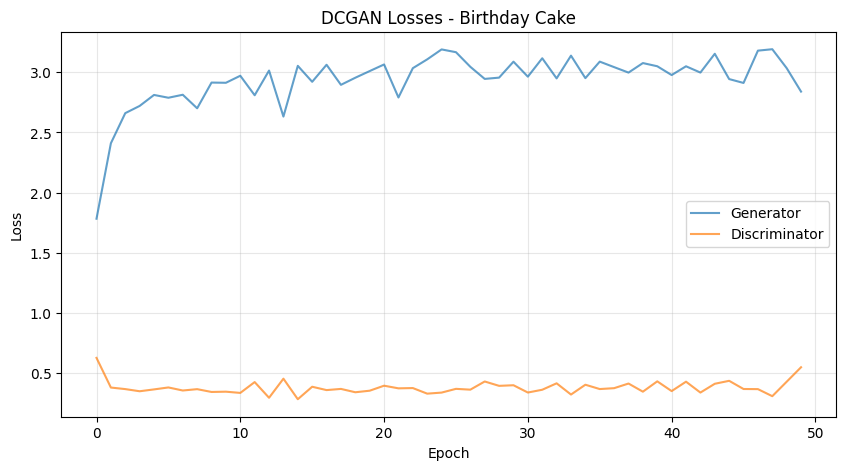

In [93]:
plt.figure(figsize=(10, 5))
plt.plot(sg_losses, label='Generator', alpha=0.7)
plt.plot(sd_losses, label='Discriminator', alpha=0.7)
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title('DCGAN Losses - Birthday Cake'); plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig('figures/part2_3/training_losses.png', dpi=150, bbox_inches='tight')
plt.show()

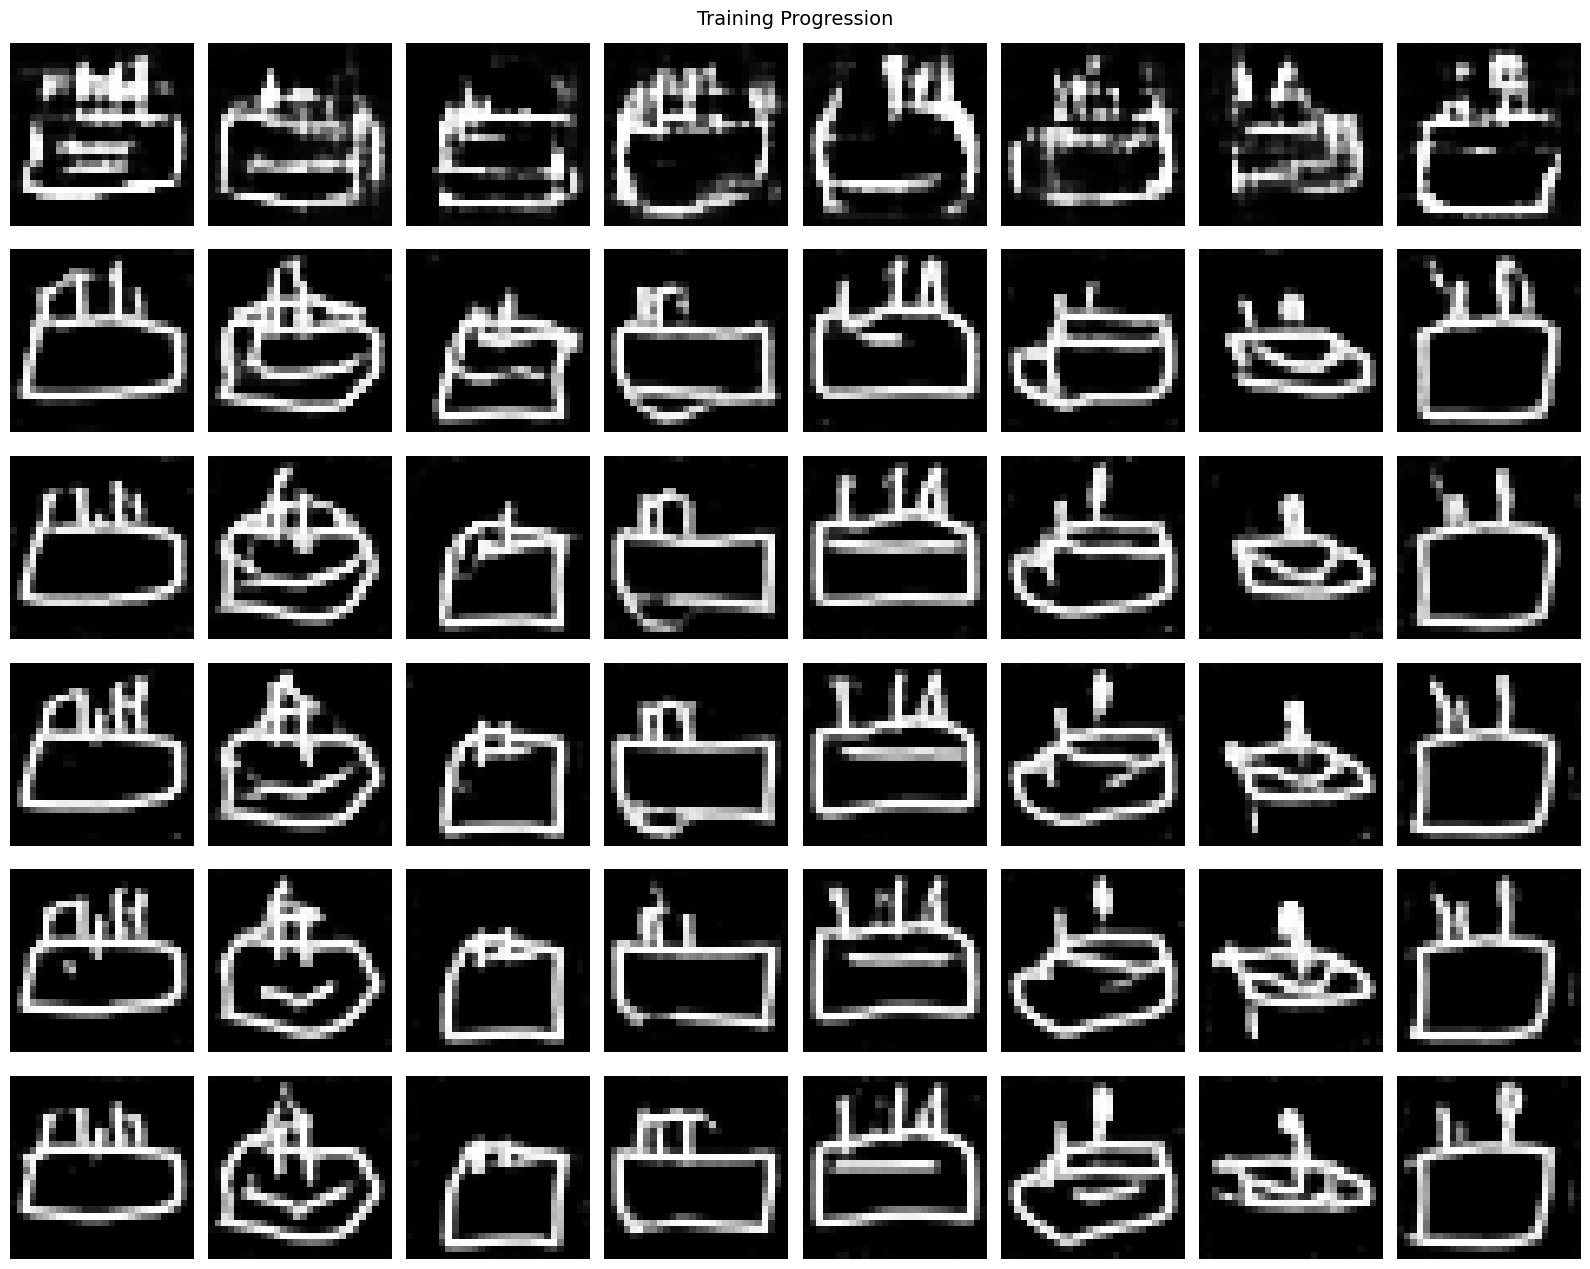

In [94]:
# training progression
n_snaps = len(sketch_snaps)
fig, axes = plt.subplots(n_snaps, 8, figsize=(16, 2*n_snaps+1))
if n_snaps == 1: axes = [axes]
for i, (ep, imgs) in enumerate(sketch_snaps):
    for j in range(8):
        axes[i][j].imshow(imgs[j].squeeze().numpy(), cmap='gray')
        axes[i][j].axis('off')
        if j == 0: axes[i][j].set_ylabel(f'ep {ep}', rotation=0, labelpad=35, fontsize=10)
plt.suptitle('Training Progression', fontsize=14)
plt.tight_layout()
plt.savefig('figures/part2_3/progression.png', dpi=150, bbox_inches='tight')
plt.show()

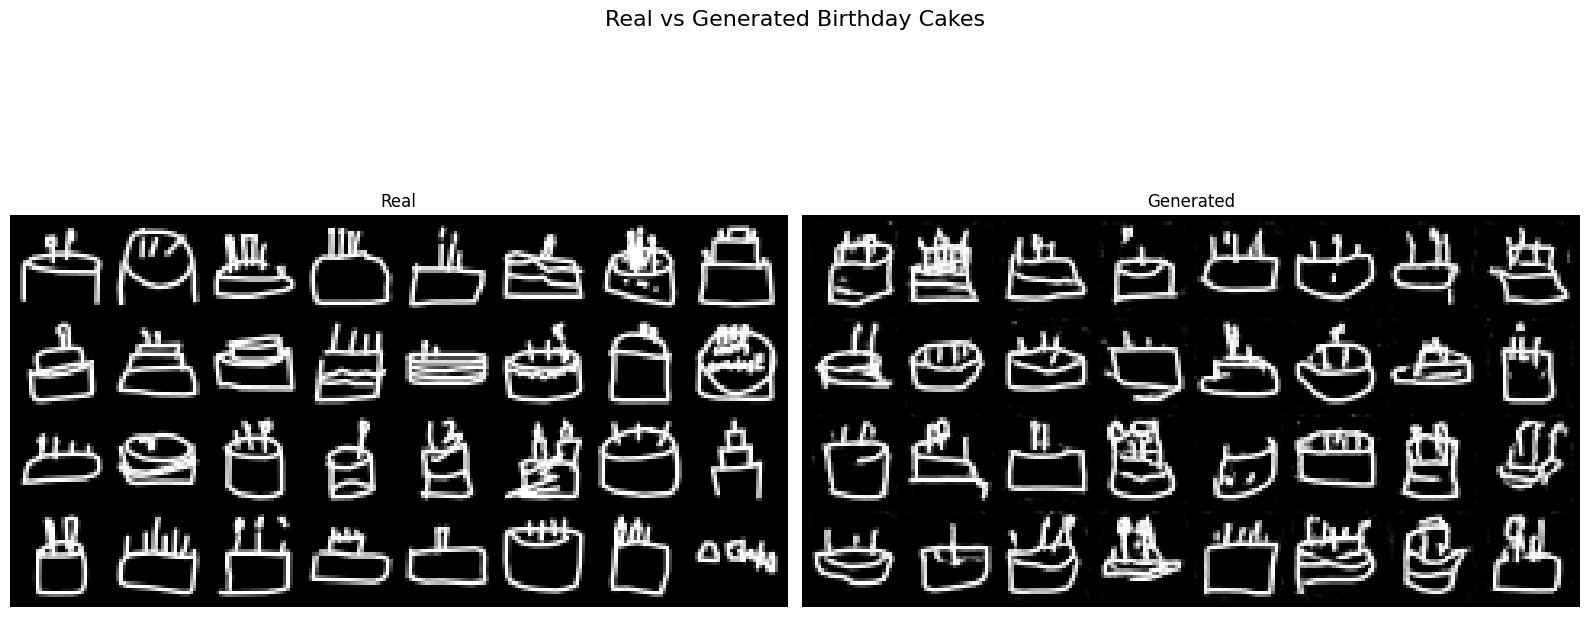

In [95]:
# real vs fake
idx = np.random.choice(len(raw), 32, replace=False)
real_t = torch.FloatTensor(raw[idx].reshape(-1,1,28,28) / 255.0)
real_grid = torchvision.utils.make_grid(real_t, nrow=8, padding=2)
sG.eval()
with torch.no_grad():
    fake = sG(torch.randn(32, LATENT_DIM, device=device)).cpu()
fake_grid = torchvision.utils.make_grid(fake, nrow=8, normalize=True, padding=2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
ax1.imshow(real_grid.permute(1,2,0).numpy(), cmap='gray'); ax1.set_title('Real'); ax1.axis('off')
ax2.imshow(fake_grid.permute(1,2,0).numpy(), cmap='gray'); ax2.set_title('Generated'); ax2.axis('off')
plt.suptitle('Real vs Generated Birthday Cakes', fontsize=16)
plt.tight_layout()
plt.savefig('figures/part2_3/real_vs_fake.png', dpi=150, bbox_inches='tight')
plt.show()

In [96]:
# FID score
print("calculating FID...")
real_fid = torch.FloatTensor(raw[:1000].reshape(-1,1,28,28).astype(np.float32) / 255.0)
real_fid = (real_fid - 0.5) / 0.5
with torch.no_grad():
    fake_fid = sG(torch.randn(1000, LATENT_DIM, device=device)).cpu()
fid_cake = calculate_fid(real_fid, fake_fid)
print(f"FID score: {fid_cake:.2f}")

calculating FID...
  extracting features...
FID score: 31.72


### Extension: Multiple Categories

In [ ]:
extra_categories = ['cat', 'house', 'tree']
extra_gens = {}

for cat in extra_categories:
    print(f"\n--- training on '{cat}' ---")
    data = download_quickdraw(cat)
    loader = make_dataloader(data, max_n=50000)

    g = SketchGenerator(LATENT_DIM, NGF).to(device)
    d = SketchDiscriminator(NDF).to(device)
    g.apply(init_weights); d.apply(init_weights)

    ext_crit = nn.BCELoss()
    go = optim.Adam(g.parameters(), lr=0.0002, betas=(0.5, 0.999))
    do = optim.Adam(d.parameters(), lr=0.0002, betas=(0.5, 0.999))

    for epoch in range(30):
        gt = dt = 0.0; cnt = 0
        for (imgs,) in loader:
            bs = imgs.size(0); imgs = imgs.to(device)
            ones = torch.ones(bs, 1, device=device)
            zeros = torch.zeros(bs, 1, device=device)
            do.zero_grad()
            z = torch.randn(bs, LATENT_DIM, device=device)
            dl = ext_crit(d(imgs), ones) + ext_crit(d(g(z).detach()), zeros)
            dl.backward(); do.step()
            go.zero_grad()
            z = torch.randn(bs, LATENT_DIM, device=device)
            gl = ext_crit(d(g(z)), ones)
            gl.backward(); go.step()
            gt += gl.item(); dt += dl.item(); cnt += 1
        if (epoch+1) % 10 == 0:
            print(f"  epoch {epoch+1}/30 | d={dt/cnt:.4f} g={gt/cnt:.4f}")
    extra_gens[cat] = g

# comparison grid
fig, axes = plt.subplots(len(extra_categories), 8, figsize=(16, 2*len(extra_categories)+1))
for i, cat in enumerate(extra_categories):
    extra_gens[cat].eval()
    with torch.no_grad():
        imgs = extra_gens[cat](torch.randn(8, LATENT_DIM, device=device)).cpu()
    for j in range(8):
        axes[i][j].imshow(imgs[j].squeeze().numpy(), cmap='gray')
        axes[i][j].axis('off')
        if j == 0: axes[i][j].set_ylabel(cat, rotation=0, labelpad=50, fontsize=11)
plt.suptitle('Multi-Category Generated Sketches', fontsize=14)
plt.tight_layout()
plt.savefig('figures/part2_3/multi_category.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nAll done!")


--- training on 'cat' ---
downloading 'cat'...
loaded 'cat': 123202 images (28x28)
  epoch 10/30 | d=0.4361 g=2.4991
